# Multi-query and grouped-query attention

Many decoder query heads can share fewer key and value heads. Grouping reduces the retained keys and values during autoregressive decoding.

The eight query heads use one, two, four or eight key-value heads. We compare an explicit repeated-array implementation with a grouped calculation on exactly the same tensors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    for column in frame.columns:
        if "error" in column.lower() or column == "Change in query norm":
            frame[column] = frame[column].map(lambda value: f"{value:.2e}")
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def softmax(logits, axis=-1):
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=axis, keepdims=True)

## Calculate grouped outputs

The group index maps each consecutive set of query heads to a single key-value head. Cache memory is calculated from the stored tensors themselves.

In [2]:
rng = np.random.default_rng(17)
heads, tokens, width = 8, 24, 6
q = rng.normal(size=(heads, 1, width)).astype(np.float32)
rows = []
for kv in [1, 2, 4, 8]:
    k, v = rng.normal(size=(2, kv, tokens, width)).astype(np.float32)
    group = heads // kv
    qr = q.reshape(kv, group, width)
    weights = softmax(np.einsum("hgd,htd->hgt", qr, k) / np.sqrt(width))
    grouped = np.einsum("hgt,htd->hgd", weights, v).reshape(heads, 1, width)
    repeated_k = np.repeat(k, group, axis=0)
    repeated_v = np.repeat(v, group, axis=0)
    reference = softmax(q @ repeated_k.transpose(0, 2, 1) / np.sqrt(width)) @ repeated_v
    err = np.max(np.abs(reference - grouped))
    assert err < 1e-5
    rows.append((kv, group, k.nbytes + v.nbytes, float(err)))
report(["KV heads", "Queries per group", "Stored KV bytes", "Max abs error vs repeat"], rows)

,KV heads,Queries per group,Stored KV bytes,Max abs error vs repeat
0,1,8,1152,1.03e-07
1,2,4,2304,8.41e-08
2,4,2,4608,7.13e-08
3,8,1,9216,2.54e-07


## Read the cache budget

Sequence length, query count, head width and precision stay fixed.

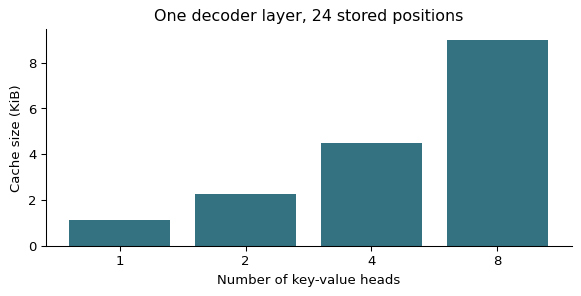

In [3]:
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
ax.bar([str(r[0]) for r in rows], [r[2] / 1024 for r in rows], color="#347181")
ax.set(
    xlabel="Number of key-value heads",
    ylabel="Cache size (KiB)",
    title="One decoder layer, 24 stored positions",
)
plt.show()

## Interpreting the result

One key-value head gives multi-query attention and eight give ordinary multi-head attention. Agreement tests compare two implementations within each setting. Quality across settings would require training and evaluation.

## Exercise

Double the sequence length and predict the new cache sizes before running the experiment.

## References

[Ainslie et al. (2023), GQA](https://arxiv.org/abs/2305.13245)